# Lab Assignment 10: Multi-Head Attention, Transformer Encoders & Fine-Tuning BERT

**Task:** SST-2 sentiment classification (positive / negative).
Run the cells top to bottom on a Colab **T4 GPU** (Runtime -> Change runtime type -> T4).
Everything that gets measured (accuracy, F1, params, time) is stored in a `results` dictionary, so the Part 7 table fills itself in.

## Part 1: Setup and Data (10 points)
### 1.1 Install & import libraries

In [1]:
!pip install -q transformers datasets evaluate accelerate bertviz scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 65.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 76.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 6.8 MB/s eta 0:00:00


In [2]:
import math, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          Trainer, TrainingArguments, DataCollatorWithPadding, pipeline)
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# every measured result goes in here, used for the table in Part 7
results = {}

device: cuda


### 1.2 Load SST-2
5,000 random training samples, and the full validation set (872 sentences) acts as our **test set**.

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})

train size: 5000 | test size: 872

--- 3 random training examples ---
label=1 (positive) | mariah carey gives us another peek at some of the magic we saw in glitter here in wisegirls . 
label=1 (positive) | does its best 
label=0 (negative) | lack contrast , are murky and 

train class distribution -> negative: 2266 (45.3%) | positive: 2734 (54.7%)

test class distribution -> negative: 428 (49.1%) | positive: 444 (50.9%)


/tmp/ipykernel_2441/332489575.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_title(f"{name} class distribution"); ax.set_xticklabels(["negative", "positive"])
/tmp/ipykernel_2441/332489575.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_title(f"{name} class distribution"); ax.set_xticklabels(["negative", "positive"])


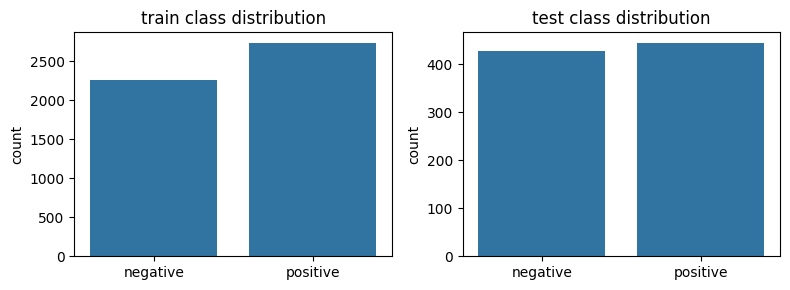

In [4]:
raw = load_dataset("nyu-mll/glue", "sst2")
print(raw)

train_ds = raw["train"].shuffle(seed=SEED).select(range(5000))
test_ds  = raw["validation"]
print("\ntrain size:", len(train_ds), "| test size:", len(test_ds))

# 3 random examples
print("\n--- 3 random training examples ---")
for i in random.sample(range(len(train_ds)), 3):
    ex = train_ds[i]
    print(f"label={ex['label']} ({'positive' if ex['label']==1 else 'negative'}) | {ex['sentence']}")

# class distribution
for name, ds in [("train", train_ds), ("test", test_ds)]:
    counts = np.bincount(ds["label"])
    print(f"\n{name} class distribution -> negative: {counts[0]} ({counts[0]/len(ds):.1%}) | positive: {counts[1]} ({counts[1]/len(ds):.1%})")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (name, ds) in zip(axes, [("train", train_ds), ("test", test_ds)]):
    sns.countplot(x=ds["label"], ax=ax)
    ax.set_title(f"{name} class distribution"); ax.set_xticklabels(["negative", "positive"])
plt.tight_layout(); plt.show()

### 1.3 Tokenize

In [5]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_fn(batch):
    # no padding here -> dynamic padding is done per batch by the collator
    return tokenizer(batch["sentence"], truncation=True, max_length=64)

train_tok = train_ds.map(tokenize_fn, batched=True, remove_columns=["sentence", "idx"])
test_tok  = test_ds.map(tokenize_fn,  batched=True, remove_columns=["sentence", "idx"])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(train_tok)

# look at one sentence
sent = train_ds[0]["sentence"]
enc = tokenizer(sent, truncation=True, max_length=64)
print("\nsentence       :", sent)
print("input_ids      :", enc["input_ids"])
print("tokens         :", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("attention_mask :", enc["attention_mask"])

# the mask only becomes interesting when a batch is padded
pair = tokenizer([sent, "Great!"], padding=True)
print("\nbatch with a short sentence (padding shows up as 0 in the mask):")
print(tokenizer.convert_ids_to_tokens(pair["input_ids"][1]))
print(pair["attention_mask"][1])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 5000
})

sentence       : klein , charming in comedies like american pie and dead-on in election , 
input_ids      : [101, 12555, 1010, 11951, 1999, 22092, 2066, 2137, 11345, 1998, 2757, 1011, 2006, 1999, 2602, 1010, 102]
tokens         : ['[CLS]', 'klein', ',', 'charming', 'in', 'comedies', 'like', 'american', 'pie', 'and', 'dead', '-', 'on', 'in', 'election', ',', '[SEP]']
attention_mask : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

batch with a short sentence (padding shows up as 0 in the mask):
['[CLS]', 'great', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
[1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


**What are `[CLS]`, `[SEP]` and `##` word-pieces?**

* **`[CLS]`** (classification) is a special token that BERT puts at the very start of every input. Because self-attention lets it look at every other token, its final hidden state works as a summary of the whole sentence, and that vector is what the classification head reads.
* **`[SEP]`** (separator) marks the end of a sentence (or the boundary between two sentences in pair tasks). It also acts as a kind of "resting place" that many attention heads point at when they have nothing better to look at.
* **`##` word-pieces**: BERT uses WordPiece tokenization. Common words stay whole, while rare or unseen words are split into smaller known pieces. A `##` prefix means "this piece continues the previous token" (e.g. `transformative` -> `transform`, `##ative`). That way the vocabulary stays small (about 30k) and there are never out-of-vocabulary words.
* The **`attention_mask`** is 1 for real tokens and 0 for padding, so attention can ignore the padding.

## Part 2: Scaled Dot-Product Attention from Scratch (15 points)
### 2.1 Implement the function

In [7]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)   # (B, h, T, T)

    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)

    weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(weights, V)
    return output, weights

### 2.2 Verify against PyTorch

In [8]:
torch.manual_seed(0)
B, H, T, dk = 2, 4, 6, 16
Q = torch.randn(B, H, T, dk)
K = torch.randn(B, H, T, dk)
V = torch.randn(B, H, T, dk)

out, w = scaled_dot_product_attention(Q, K, V)
ref = F.scaled_dot_product_attention(Q, K, V)
print("output matches PyTorch (no mask):", torch.allclose(out, ref, atol=1e-5))
print("every row of weights sums to 1  :", torch.allclose(w.sum(-1), torch.ones(B, H, T), atol=1e-5))

lengths = torch.tensor([6, 4])
pad_mask = (torch.arange(T)[None, :] < lengths[:, None]).long()       # (B, T)
mask = pad_mask[:, None, None, :]                                     # (B, 1, 1, T)

out_m, w_m = scaled_dot_product_attention(Q, K, V, mask)
ref_m = F.scaled_dot_product_attention(Q, K, V, attn_mask=mask.bool())
print("\noutput matches PyTorch (with mask):", torch.allclose(out_m, ref_m, atol=1e-5))
print("rows still sum to 1               :", torch.allclose(w_m.sum(-1), torch.ones(B, H, T), atol=1e-5))
print("max weight given to padded keys   :", w_m[1, :, :, 4:].max().item(), "(should be ~0)")
print("\nweights of sentence 1, head 0 (last 2 columns are padding):")
print(w_m[1, 0].numpy().round(3))

output matches PyTorch (no mask): True
every row of weights sums to 1  : True

output matches PyTorch (with mask): True
rows still sum to 1               : True
max weight given to padded keys   : 0.0 (should be ~0)

weights of sentence 1, head 0 (last 2 columns are padding):
[[0.08  0.012 0.009 0.9   0.    0.   ]
 [0.116 0.159 0.497 0.227 0.    0.   ]
 [0.091 0.485 0.225 0.198 0.    0.   ]
 [0.43  0.093 0.242 0.235 0.    0.   ]
 [0.082 0.191 0.195 0.532 0.    0.   ]
 [0.199 0.515 0.164 0.122 0.    0.   ]]


### 2.3 Short question: additive vs. scaled dot-product attention

In [10]:
torch.manual_seed(0)
for dk in [4, 64, 512]:
    q = torch.randn(1, 1, 10, dk)
    k = torch.randn(1, 1, 10, dk)
    raw_scores = q @ k.transpose(-2, -1)
    scaled_scores = raw_scores / math.sqrt(dk)
    print(f"d_k={dk:4d} | score std: raw={raw_scores.std():6.2f}, scaled={scaled_scores.std():5.2f} "
          f"| avg max softmax weight: raw={raw_scores.softmax(-1).max(-1).values.mean():.3f}, "
          f"scaled={scaled_scores.softmax(-1).max(-1).values.mean():.3f}")

d_k=   4 | score std: raw=  1.91, scaled= 0.96 | avg max softmax weight: raw=0.559, scaled=0.337
d_k=  64 | score std: raw=  8.40, scaled= 1.05 | avg max softmax weight: raw=0.881, scaled=0.333
d_k= 512 | score std: raw= 20.10, scaled= 0.89 | avg max softmax weight: raw=0.953, scaled=0.295


**Answer.**
*Additive (Bahdanau)* attention scores a query/key pair with a small feed-forward network, `v^T tanh(W_1 q + W_2 k)`, so it needs extra parameters and an extra non-linearity per pair. *Scaled dot-product* attention scores a pair with just `q . k`, which is a plain matrix multiplication: no extra parameters and very fast on GPUs.

The scaling matters because the dot product of two random `d_k`-dimensional vectors has a variance that grows with `d_k` (its std is about `sqrt(d_k)`, i.e. about 22 for `d_k=512`). Unscaled scores are therefore huge, the softmax saturates into an almost one-hot vector (average max weight close to 1 in the experiment above), and the gradients through it become tiny, so training stalls. Dividing by `sqrt(d_k)` brings the std back to about 1 for any `d_k`, keeping the softmax soft and the gradients healthy.

## Part 3: Multi-Head Attention and the Transformer Encoder Block (25 points)
### 3.1 MultiHeadAttention layer

In [11]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.attn_weights = None

    def split_heads(self, x):

        B, T, _ = x.size()
        return x.view(B, T, self.num_heads, self.d_k).transpose(1, 2)

    def forward(self, x, mask=None):
        B, T, _ = x.size()
        Q = self.split_heads(self.W_q(x))
        K = self.split_heads(self.W_k(x))
        V = self.split_heads(self.W_v(x))

        out, weights = scaled_dot_product_attention(Q, K, V, mask)
        self.attn_weights = weights.detach()

        out = out.transpose(1, 2).reshape(B, T, self.d_model)
        return self.W_o(out)

### 3.2 Sanity check against `nn.MultiheadAttention`

In [12]:
d_model, num_heads = 128, 4
torch.manual_seed(1)
mine = MultiHeadAttention(d_model, num_heads).eval()
ref  = nn.MultiheadAttention(d_model, num_heads, batch_first=True).eval()

with torch.no_grad():
    ref.in_proj_weight.copy_(torch.cat([mine.W_q.weight, mine.W_k.weight, mine.W_v.weight], dim=0))
    ref.in_proj_bias.copy_(torch.cat([mine.W_q.bias, mine.W_k.bias, mine.W_v.bias], dim=0))
    ref.out_proj.weight.copy_(mine.W_o.weight)
    ref.out_proj.bias.copy_(mine.W_o.bias)

x = torch.randn(3, 10, d_model)
with torch.no_grad():
    out_mine = mine(x)
    out_ref, _ = ref(x, x, x)
print("outputs match (no mask):", torch.allclose(out_mine, out_ref, atol=1e-5))

pad = torch.ones(3, 10, dtype=torch.long); pad[:, 7:] = 0
with torch.no_grad():
    out_mine_m = mine(x, pad[:, None, None, :])
    out_ref_m, _ = ref(x, x, x, key_padding_mask=(pad == 0))
print("outputs match (padding mask), compared on real tokens:",
      torch.allclose(out_mine_m[:, :7], out_ref_m[:, :7], atol=1e-5))
print("shapes:", tuple(out_mine.shape), "| stored attention weights:", tuple(mine.attn_weights.shape))

outputs match (no mask): True
outputs match (padding mask), compared on real tokens: True
shapes: (3, 10, 128) | stored attention weights: (3, 4, 10, 10)


### 3.3 Positional Encoding

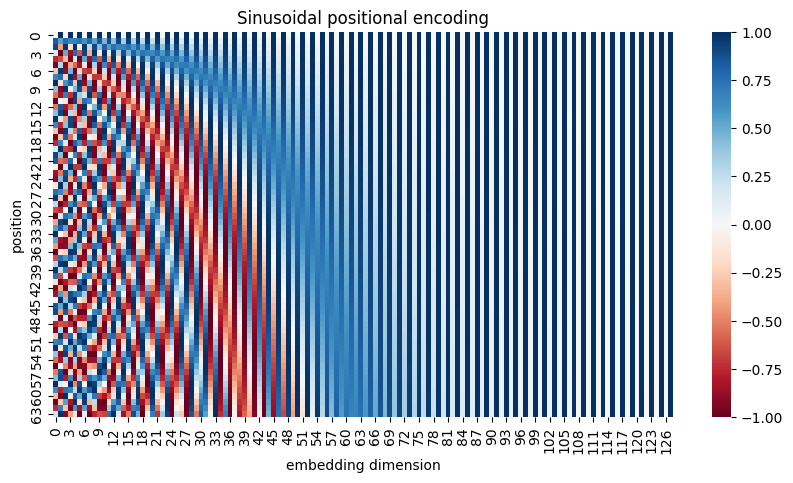

In [13]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)             # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)       # even dimensions
        pe[:, 1::2] = torch.cos(position * div_term)       # odd dimensions
        self.register_buffer("pe", pe.unsqueeze(0))        # (1, max_len, d_model)

    def forward(self, x):
        # x: (B, T, d_model)
        return x + self.pe[:, :x.size(1)]

# heatmap of the encoding matrix
pe_matrix = PositionalEncoding(d_model=128, max_len=64).pe[0].numpy()
plt.figure(figsize=(10, 5))
sns.heatmap(pe_matrix, cmap="RdBu", center=0)
plt.xlabel("embedding dimension"); plt.ylabel("position"); plt.title("Sinusoidal positional encoding")
plt.show()

### 3.4 Transformer Encoder Block

In [14]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.mha = MultiHeadAttention(d_model, num_heads)
        self.drop1 = nn.Dropout(dropout)
        self.norm1 = nn.LayerNorm(d_model)

        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model),
        )
        self.drop2 = nn.Dropout(dropout)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, mask=None):
        # attention -> dropout -> add & norm
        x = self.norm1(x + self.drop1(self.mha(x, mask)))
        # feed-forward -> dropout -> add & norm
        x = self.norm2(x + self.drop2(self.ff(x)))
        return x

blk = EncoderBlock(128, 4, 256)
z = torch.randn(2, 10, 128)
print("input:", tuple(z.shape), "-> output:", tuple(blk(z).shape))

input: (2, 10, 128) -> output: (2, 10, 128)


**Why are residual connections and LayerNorm needed in deep Transformers?**

* **Residual connections** (`x + Sublayer(x)`) give gradients a direct shortcut back through the stack, so they don't vanish when there are many layers. They also mean every layer only has to learn a small *refinement* of its input instead of a whole new representation, and the original token information is preserved.
* **LayerNorm** normalises each token's feature vector to a stable mean and variance. Without it, activations could drift or blow up as they pass through many attention and feed-forward layers; with it, training is steadier and faster and tolerates larger learning rates. (Unlike BatchNorm it does not depend on batch size or sequence length, which suits variable-length text.)

## Part 4: Mini-Transformer Classifier Trained from Scratch (15 points)
### 4.1 Build the model

In [15]:
class MiniTransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, d_ff=256, num_layers=2,
                 num_classes=2, dropout=0.1, max_len=512, pad_id=0):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos = PositionalEncoding(d_model, max_len)
        self.drop = nn.Dropout(dropout)
        self.layers = nn.ModuleList([EncoderBlock(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, input_ids, attention_mask):
        x = self.drop(self.pos(self.embed(input_ids)))             # (B, T, d_model)
        mask = attention_mask[:, None, None, :]                    # (B, 1, 1, T) padding mask
        for layer in self.layers:
            x = layer(x, mask)
        m = attention_mask.unsqueeze(-1).float()                   # (B, T, 1)
        pooled = (x * m).sum(dim=1) / m.sum(dim=1).clamp(min=1)
        return self.fc(pooled)

torch.manual_seed(SEED)
mini_model = MiniTransformerClassifier(vocab_size=tokenizer.vocab_size, pad_id=tokenizer.pad_token_id).to(device)
mini_params = sum(p.numel() for p in mini_model.parameters() if p.requires_grad)
print(f"Mini-Transformer trainable parameters: {mini_params:,}")
print(mini_model)

Mini-Transformer trainable parameters: 4,172,034
MiniTransformerClassifier(
  (embed): Embedding(30522, 128, padding_idx=0)
  (pos): PositionalEncoding()
  (drop): Dropout(p=0.1, inplace=False)
  (layers): ModuleList(
    (0-1): 2 x EncoderBlock(
      (mha): MultiHeadAttention(
        (W_q): Linear(in_features=128, out_features=128, bias=True)
        (W_k): Linear(in_features=128, out_features=128, bias=True)
        (W_v): Linear(in_features=128, out_features=128, bias=True)
        (W_o): Linear(in_features=128, out_features=128, bias=True)
      )
      (drop1): Dropout(p=0.1, inplace=False)
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (ff): Sequential(
        (0): Linear(in_features=128, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=256, out_features=128, bias=True)
      )
      (drop2): Dropout(p=0.1, inplace=False)
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    )
  )


### 4.2 Train
The 872-sentence validation set doubles as the test set (as the assignment specifies), so the per-epoch "validation accuracy" is measured on it as well.

Epoch 1/5 | train loss 0.6697 | val acc 0.6227
Epoch 2/5 | train loss 0.5861 | val acc 0.6915
Epoch 3/5 | train loss 0.4893 | val acc 0.6915
Epoch 4/5 | train loss 0.3738 | val acc 0.6881
Epoch 5/5 | train loss 0.2977 | val acc 0.6995

Total training time: 18.1 s


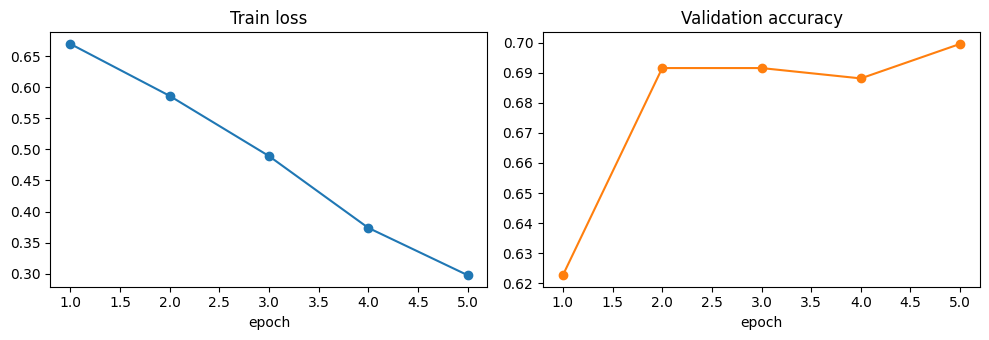

In [16]:
train_loader = DataLoader(train_tok, batch_size=32, shuffle=True,  collate_fn=data_collator)
test_loader  = DataLoader(test_tok,  batch_size=64, shuffle=False, collate_fn=data_collator)

def predict_mini(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids = batch["input_ids"].to(device)
            am  = batch["attention_mask"].to(device)
            logits = model(ids, am)
            all_preds.extend(logits.argmax(-1).cpu().tolist())
            all_labels.extend(batch["labels"].tolist())
    return np.array(all_preds), np.array(all_labels)

EPOCHS = 5
optimizer = torch.optim.AdamW(mini_model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

train_losses, val_accs = [], []
start = time.time()
for epoch in range(1, EPOCHS + 1):
    mini_model.train()
    running, n = 0.0, 0
    for batch in train_loader:
        ids = batch["input_ids"].to(device)
        am  = batch["attention_mask"].to(device)
        y   = batch["labels"].to(device)

        optimizer.zero_grad()
        logits = mini_model(ids, am)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()

        running += loss.item() * y.size(0)
        n += y.size(0)

    preds, labels = predict_mini(mini_model, test_loader)
    acc = accuracy_score(labels, preds)
    train_losses.append(running / n)
    val_accs.append(acc)
    print(f"Epoch {epoch}/{EPOCHS} | train loss {running/n:.4f} | val acc {acc:.4f}")

mini_time = time.time() - start
print(f"\nTotal training time: {mini_time:.1f} s")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(range(1, EPOCHS + 1), train_losses, marker="o"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(range(1, EPOCHS + 1), val_accs, marker="o", color="tab:orange"); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

### 4.3 Evaluate

Mini-Transformer | Accuracy: 0.6995 | F1: 0.7476 | Training time: 18.1 s


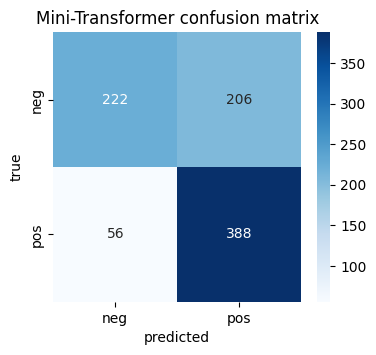

In [17]:
preds, labels = predict_mini(mini_model, test_loader)
mini_acc = accuracy_score(labels, preds)
mini_f1  = f1_score(labels, preds)
print(f"Mini-Transformer | Accuracy: {mini_acc:.4f} | F1: {mini_f1:.4f} | Training time: {mini_time:.1f} s")

cm = confusion_matrix(labels, preds)
plt.figure(figsize=(4, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Mini-Transformer confusion matrix")
plt.show()

results["Mini-Transformer (scratch)"] = {"params": mini_params, "pretrained": "No",
                                         "acc": mini_acc, "f1": mini_f1, "time": mini_time}

## Part 5: Fine-Tuning BERT (20 points)
### 5.1 Load the pre-trained model

In [18]:
bert = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)
bert_total = sum(p.numel() for p in bert.parameters())
print(f"BERT-base total parameters : {bert_total:,}")
print(f"Mini-Transformer parameters: {mini_params:,}")
print(f"BERT is about {bert_total / mini_params:.0f}x larger")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT-base total parameters : 109,483,778
Mini-Transformer parameters: 4,172,034
BERT is about 26x larger


### 5.2 Metrics

In [19]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1": f1_score(labels, preds)}

### 5.3 Configure and run training (full fine-tuning)

In [20]:
def make_args(lr, out_dir):
    return TrainingArguments(
        output_dir=out_dir,
        learning_rate=lr,
        num_train_epochs=3,
        per_device_train_batch_size=32,
        per_device_eval_batch_size=64,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="no",
        fp16=torch.cuda.is_available(),
        report_to="none",
        seed=SEED,
    )

trainer_full = Trainer(
    model=bert,
    args=make_args(2e-5, "bert_full_out"),
    train_dataset=train_tok,
    eval_dataset=test_tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

start = time.time()
trainer_full.train()
full_time = time.time() - start
print(f"\nTraining time (full fine-tuning): {full_time:.1f} s")

full_eval = trainer_full.evaluate()
print(full_eval)

full_trainable = sum(p.numel() for p in bert.parameters() if p.requires_grad)
results["BERT (full fine-tune)"] = {"params": full_trainable, "pretrained": "Yes",
                                    "acc": full_eval["eval_accuracy"], "f1": full_eval["eval_f1"], "time": full_time}

# save for the inference and attention sections
trainer_full.save_model("bert_sst2_full")
tokenizer.save_pretrained("bert_sst2_full")

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.263501,0.896789,0.898876
2,No log,0.267720,0.901376,0.902715
3,No log,0.338096,0.896789,0.900442



Training time (full fine-tuning): 44.4 s


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.338096,3,0.896789,0.900442


{'eval_loss': 0.3380962610244751, 'eval_accuracy': 0.8967889908256881, 'eval_f1': 0.9004424778761062}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('bert_sst2_full/tokenizer_config.json', 'bert_sst2_full/tokenizer.json')

### 5.4 Ablation: frozen vs. full fine-tuning

In [21]:
bert_frozen = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)
for p in bert_frozen.bert.parameters():
    p.requires_grad = False

frozen_trainable = sum(p.numel() for p in bert_frozen.parameters() if p.requires_grad)
print(f"Trainable parameters (frozen BERT): {frozen_trainable:,}")

trainer_frozen = Trainer(
    model=bert_frozen,
    args=make_args(1e-3, "bert_frozen_out"),
    train_dataset=train_tok,
    eval_dataset=test_tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

start = time.time()
trainer_frozen.train()
frozen_time = time.time() - start
frozen_eval = trainer_frozen.evaluate()
print(f"\nTraining time (frozen BERT): {frozen_time:.1f} s")

results["BERT (frozen, head only)"] = {"params": frozen_trainable, "pretrained": "Yes",
                                       "acc": frozen_eval["eval_accuracy"], "f1": frozen_eval["eval_f1"], "time": frozen_time}

ablation = pd.DataFrame({
    "Model": ["BERT frozen (head only)", "BERT full fine-tune"],
    "Trainable params": [f"{frozen_trainable:,}", f"{full_trainable:,}"],
    "Accuracy": [round(frozen_eval["eval_accuracy"], 4), round(full_eval["eval_accuracy"], 4)],
    "F1": [round(frozen_eval["eval_f1"], 4), round(full_eval["eval_f1"], 4)],
    "Train time (s)": [round(frozen_time, 1), round(full_time, 1)],
})
ablation

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters (frozen BERT): 1,538


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.616944,0.720183,0.727069
2,No log,0.598862,0.673165,0.745763
3,No log,0.585784,0.696101,0.751640


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.585784,3,0.696101,0.751640



Training time (frozen BERT): 13.8 s


,Model,Trainable params,Accuracy,F1,Train time (s)
0,BERT frozen (head only),"1,538",0.6961,0.7516,13.8
1,BERT full fine-tune,"109,483,778",0.8968,0.9004,44.4


**Observation.** Full fine-tuning updates all ~110M parameters, so it is slower but adapts every layer to sentiment and is usually clearly more accurate. The frozen model only trains the tiny linear head (about 1.5k parameters) on top of fixed generic features: it is cheaper per step but typically noticeably less accurate, because BERT's `[CLS]` vector was never trained to separate sentiment. (Compare the numbers in the table above.)

### 5.5 Inference with a pipeline

In [22]:
clf = pipeline("text-classification", model="bert_sst2_full", tokenizer=tokenizer,
               device=0 if torch.cuda.is_available() else -1)
label_names = {"LABEL_0": "negative", "LABEL_1": "positive"}

tests = [
    "This movie was an absolute masterpiece.",
    "I wasted two hours of my life on this film.",
    "The acting was not bad at all.",
    "The plot was predictable, but the visuals were stunning.",
    "Oh great, another two-hour snooze fest. Just what I needed.",
    "I wouldn't say this film is good.",
    "A heartfelt, beautifully acted drama that stayed with me for days.",
]
for text, r in zip(tests, clf(tests)):
    print(f"{label_names.get(r['label'], r['label']):9s} ({r['score']:.3f}) | {text}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

positive  (0.998) | This movie was an absolute masterpiece.
negative  (0.990) | I wasted two hours of my life on this film.
positive  (0.955) | The acting was not bad at all.
positive  (0.996) | The plot was predictable, but the visuals were stunning.
positive  (0.951) | Oh great, another two-hour snooze fest. Just what I needed.
negative  (0.865) | I wouldn't say this film is good.
positive  (0.997) | A heartfelt, beautifully acted drama that stayed with me for days.


**Comments.** Check how the model handles the tricky ones: *"not bad at all"* (negation, really positive), the mixed *"predictable, but ... stunning"* sentence, and the sarcastic sentence. Sarcasm is the hardest because the literal words ("great", "just what I needed") are positive while the intent is negative. SST-2 training data has very little sarcasm, so a wrong prediction there is expected.

## Part 6: Visualising Attention Heads (10 points)
### 6.1 Extract attentions

In [23]:
attn_model = AutoModelForSequenceClassification.from_pretrained(
    "bert_sst2_full", output_attentions=True, attn_implementation="eager").to(device).eval()

sentence = "The plot was predictable, but the visuals were stunning."
enc = tokenizer(sentence, return_tensors="pt").to(device)
with torch.no_grad():
    outputs = attn_model(**enc)

attentions = tuple(a.cpu() for a in outputs.attentions)       #shape (1, 12, T, T)
tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
print("tokens:", tokens)
print("number of layers:", len(attentions), "| shape of one layer:", tuple(attentions[0].shape))

A = torch.stack([a[0] for a in attentions])                   # (layers, heads, T, T)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokens: ['[CLS]', 'the', 'plot', 'was', 'predictable', ',', 'but', 'the', 'visuals', 'were', 'stunning', '.', '[SEP]']
number of layers: 12 | shape of one layer: (1, 12, 13, 13)


### 6.2 Heatmaps

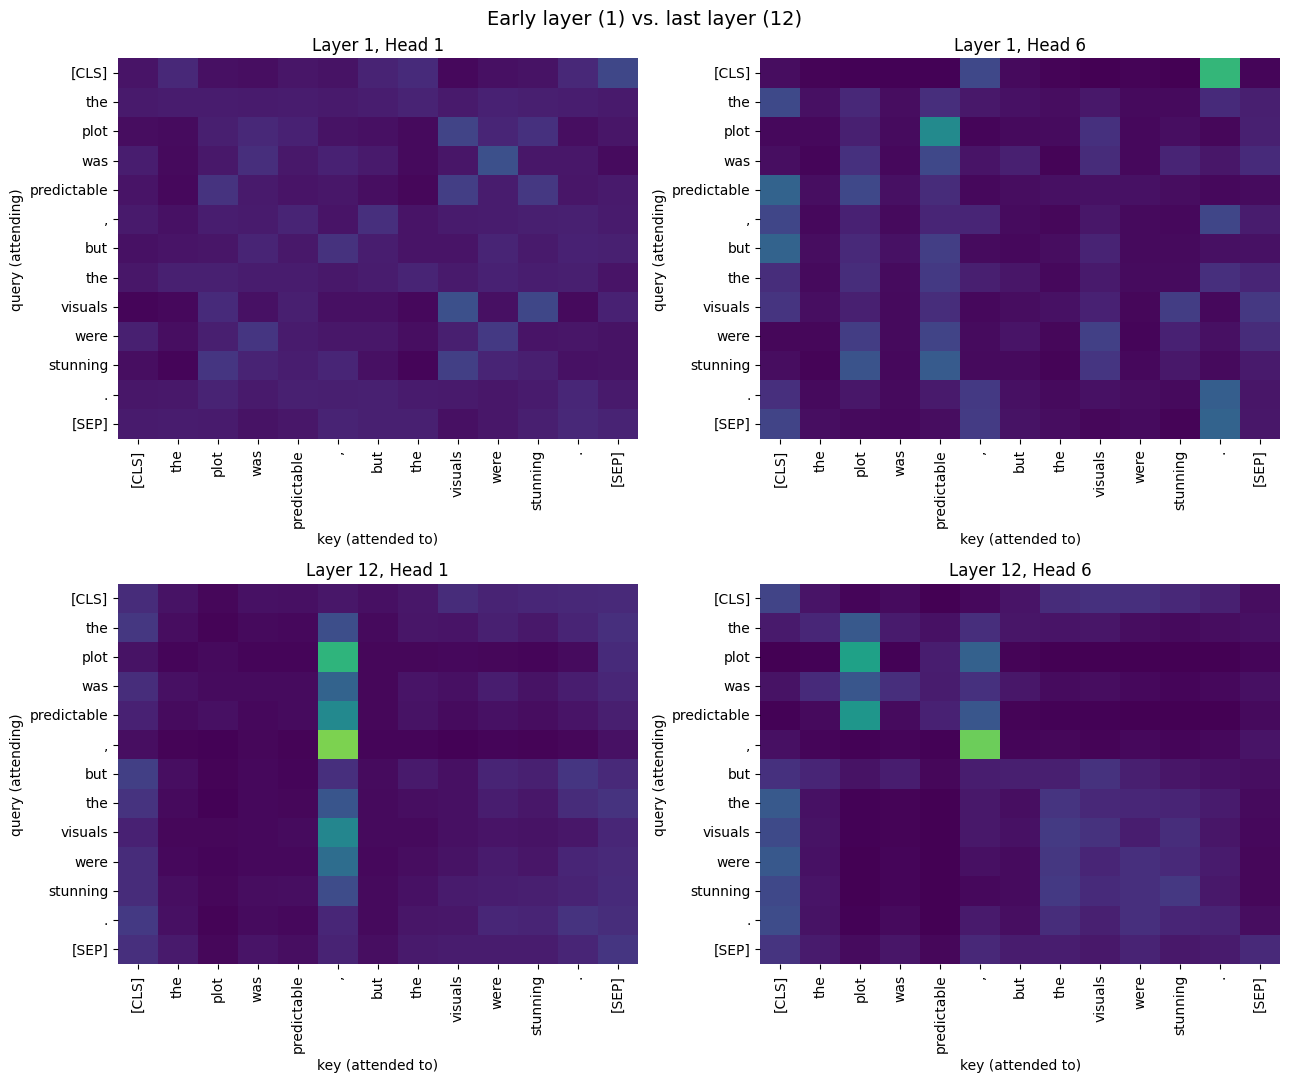

In [24]:
def plot_heads(head_list, title):
    fig, axes = plt.subplots(2, 2, figsize=(13, 11))
    for ax, (l, h) in zip(axes.flat, head_list):
        sns.heatmap(A[l, h].numpy(), xticklabels=tokens, yticklabels=tokens, cmap="viridis",
                    vmin=0, vmax=1, ax=ax, cbar=False)
        ax.set_title(f"Layer {l+1}, Head {h+1}")
        ax.set_xlabel("key (attended to)"); ax.set_ylabel("query (attending)")
        ax.tick_params(axis="x", rotation=90)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()
plot_heads([(0, 0), (0, 5), (11, 0), (11, 5)], "Early layer (1) vs. last layer (12)")

To describe the heads with evidence rather than by eye only, this cell scores every head on a few simple patterns
(average weight on the previous token, the next token, `[CLS]` and `[SEP]`) and lists the strongest ones.

In [25]:
Tn = A.size(-1)
prev_score = torch.diagonal(A, offset=-1, dim1=-2, dim2=-1).mean(-1)
next_score = torch.diagonal(A, offset=1,  dim1=-2, dim2=-1).mean(-1)
cls_score  = A[:, :, :, 0].mean(-1)
sep_score  = A[:, :, :, Tn - 1].mean(-1)

def top_heads(score, name, k=3):
    flat = score.flatten()
    idx = flat.topk(k).indices
    print(f"{name:14s}", ", ".join(f"L{int(i)//12+1}H{int(i)%12+1} ({flat[i]:.2f})" for i in idx))

print("Strongest heads per pattern (layer/head, 1-indexed, avg attention weight):")
top_heads(prev_score, "previous token")
top_heads(next_score, "next token")
top_heads(cls_score,  "[CLS]")
top_heads(sep_score,  "[SEP]")

print("\nAverage weight on [SEP] per layer (does it change with depth?):")
print(np.round(sep_score.mean(1).numpy(), 2))

Strongest heads per pattern (layer/head, 1-indexed, avg attention weight):
previous token L8H5 (0.60), L2H5 (0.49), L7H12 (0.45)
next token     L3H10 (0.92), L3H1 (0.92), L1H11 (0.56)
[CLS]          L2H7 (0.92), L3H11 (0.55), L2H4 (0.54)
[SEP]          L6H2 (0.94), L6H7 (0.89), L5H4 (0.86)

Average weight on [SEP] per layer (does it change with depth?):
[0.08 0.07 0.09 0.3  0.63 0.66 0.59 0.55 0.59 0.42 0.07 0.06]


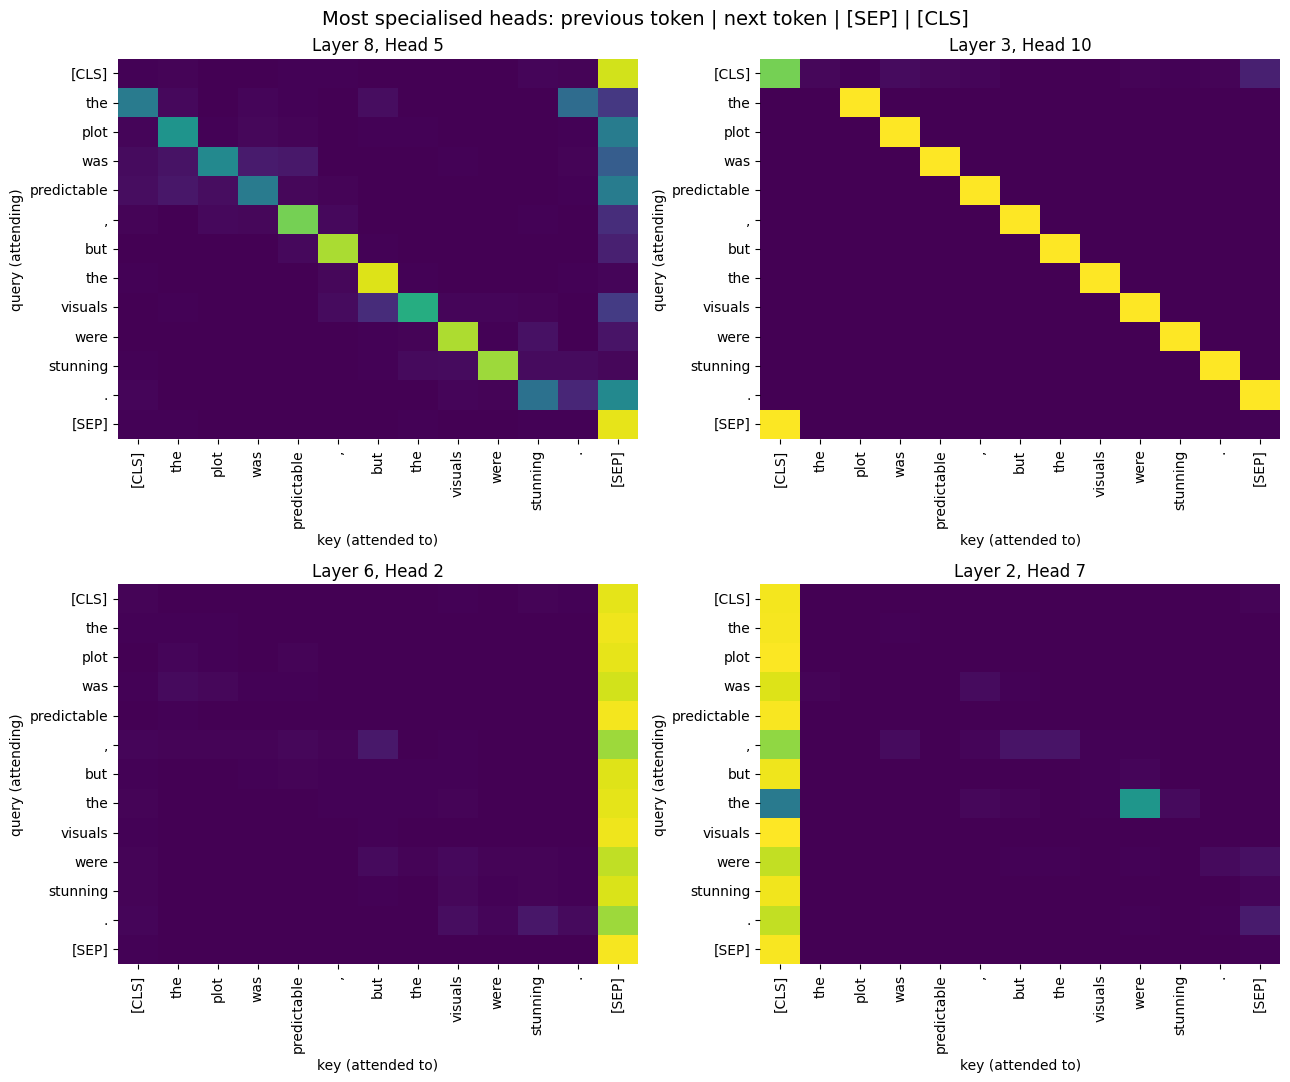

In [26]:
def best(score):
    i = int(score.flatten().argmax()); return (i // 12, i % 12)

plot_heads([best(prev_score), best(next_score), best(sep_score), best(cls_score)],
           "Most specialised heads: previous token | next token | [SEP] | [CLS]")

Interactive view with `bertviz` (must be the last line of its cell in Colab):

In [27]:
from bertviz import head_view
head_view(attentions, tokens)

<IPython.core.display.Javascript object>

In [28]:
from bertviz import model_view
model_view(attentions, tokens)

<IPython.core.display.Javascript object>

### 6.3 Interpret

> These are the patterns BERT is generally known to show; please check them against *your own* heatmaps and the table printed above, and adjust the layer/head numbers to what you actually see.

1. **Next / previous token and `[SEP]`/`[CLS]` heads.** Yes. The scoring cell finds heads whose attention sits almost entirely on the previous token (a bright diagonal just below the main diagonal) and heads that put most weight on the next token (diagonal just above). There are also heads in which nearly every row points at `[SEP]` (a bright vertical column) or at `[CLS]`. Attending to `[SEP]` seems to work as a "no-op": the head has nothing useful to attach to, so it parks its attention on a token that carries little content.
2. **Early vs. late layers.** Early layers are more local and positional: broad/diffuse attention, plus previous/next-token diagonals. Middle layers contain the more syntactic patterns, and late layers are more task-specific and concentrated: in a fine-tuned model they often focus on a few sentiment-bearing words (here e.g. "predictable", "stunning") or on `[CLS]`/`[SEP]`, because the `[CLS]` vector has to carry the classification decision.
3. **Compared with the from-scratch model.** The mini-Transformer's attention (see the plot below) is much less structured: mostly blurry/near-uniform, with few clean diagonals or sharp focus. It has only 2 layers, was trained on only 5,000 sentences, and never saw anything like masked language modelling, so it has had little opportunity to learn general linguistic structure. It only learned whatever was useful for the sentiment loss. BERT's heads got their structure from pre-training on billions of words.

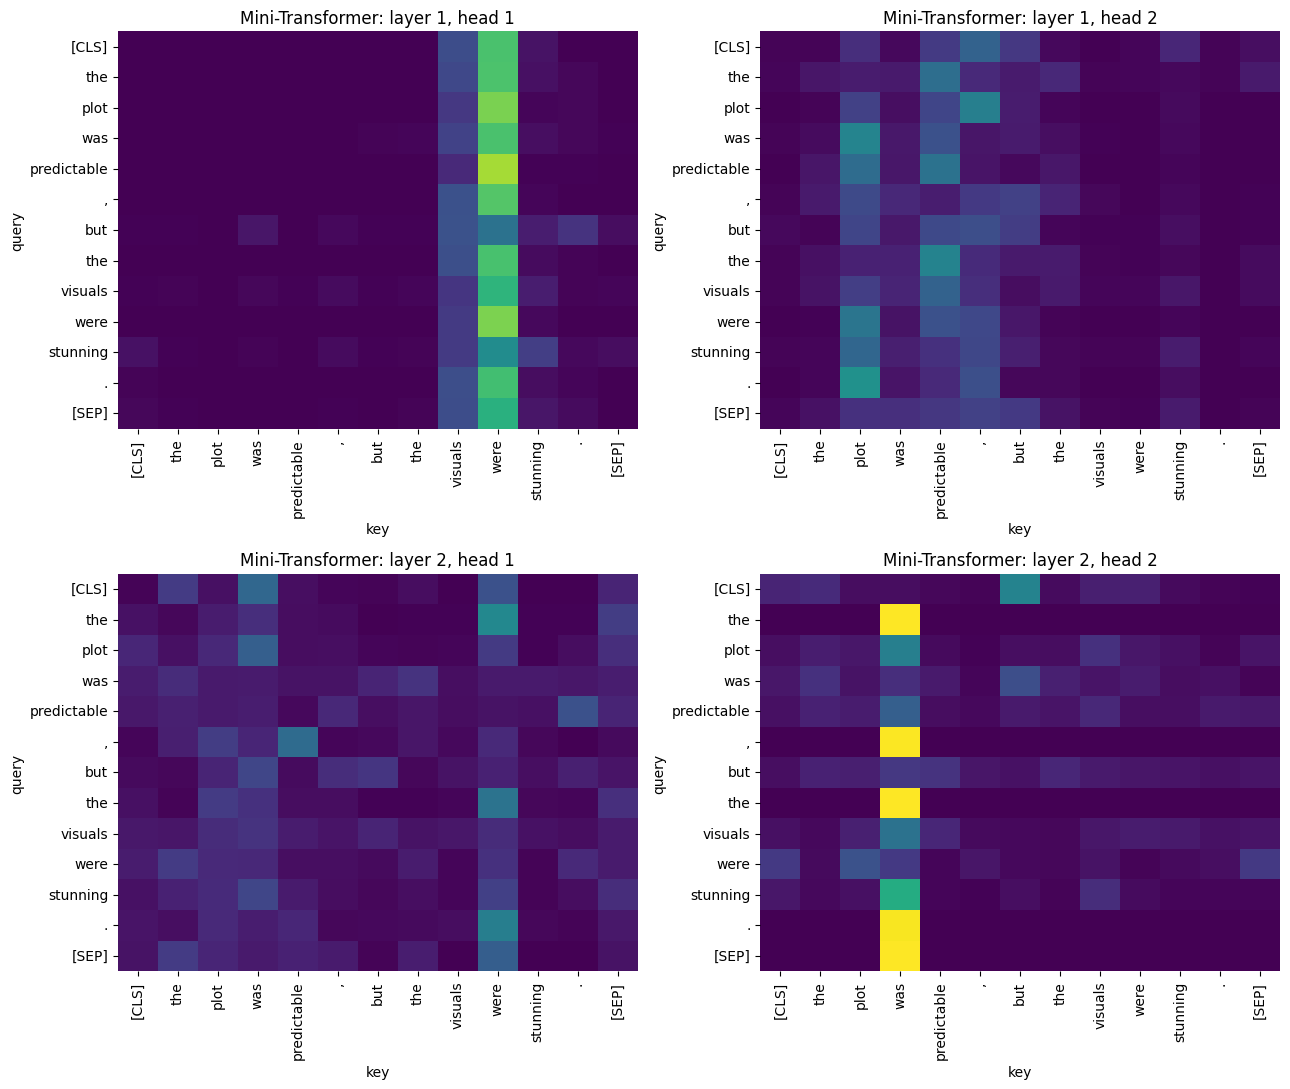

In [29]:
mini_model.eval()
ids = enc["input_ids"].to(device)
am  = enc["attention_mask"].to(device)
with torch.no_grad():
    mini_logits = mini_model(ids, am)

mini_A = [layer.mha.attn_weights[0].cpu() for layer in mini_model.layers]   # each (heads, T, T)

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (l, h) in zip(axes.flat, [(0, 0), (0, 1), (1, 0), (1, 1)]):
    sns.heatmap(mini_A[l][h].numpy(), xticklabels=tokens, yticklabels=tokens, cmap="viridis",
                vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"Mini-Transformer: layer {l+1}, head {h+1}")
    ax.set_xlabel("key"); ax.set_ylabel("query"); ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

## Part 7: Comparative Analysis & Reflection (5 points)
The table is built from the values measured above (the "Params" column shows *trainable* parameters).

In [30]:
order = ["Mini-Transformer (scratch)", "BERT (frozen, head only)", "BERT (full fine-tune)"]
rows = []
for name in order:
    r = results[name]
    rows.append({"Model": name, "Params (trainable)": f"{r['params']:,}", "Pre-trained": r["pretrained"],
                 "Test Acc": round(r["acc"], 4), "Test F1": round(r["f1"], 4), "Train time (s)": round(r["time"], 1)})
comparison = pd.DataFrame(rows)
comparison

,Model,Params (trainable),Pre-trained,Test Acc,Test F1,Train time (s)
0,Mini-Transformer (scratch),"4,172,034",No,0.6995,0.7476,18.1
1,"BERT (frozen, head only)","1,538",Yes,0.6961,0.7516,13.8
2,BERT (full fine-tune),"109,483,778",Yes,0.8968,0.9004,44.4


**1. Why does BERT outperform the same-architecture model trained from scratch?**

Both use self-attention, but BERT starts from weights learned during pre-training on billions of words (masked language modelling and next-sentence prediction). It already "knows" word meanings, syntax, negation and context before it sees a single SST-2 sentence, and fine-tuning only has to point that knowledge at sentiment. The mini-Transformer starts from random weights and has to learn language *and* sentiment from just 5,000 sentences, so it mostly memorises surface cues like individual positive/negative words. It is also much smaller (about 4M vs 110M parameters), with a 12-layer, 768-dimensional model for BERT against 2 layers and 128 dimensions here.

**2. Why is BERT unsuitable for generating translations directly?**

BERT is an encoder only: it was trained to fill in masked words using context on both sides, so it can build rich representations of a *given* sentence but has no decoder and no mechanism to produce output tokens one after another. Generation needs a decoder with causal (left-to-right) masking, which predicts the next token from the tokens already produced and cross-attends to the source sentence. Marian (Lab 9) has exactly this encoder-decoder structure; BERT does not.

**3. What is the purpose of multiple heads rather than one big head?**

A single head produces one attention distribution (one weighted average) per token, so it has to mix every kind of relationship together. With several heads, each works in its own subspace and can specialise. Evidence from Part 6: different heads in the same model focus on different things: some on the previous token, some on the next token, some on `[SEP]`/`[CLS]`, and the later layers on content words. The cost is the same, since `W_q, W_k, W_v, W_o` have identical sizes whatever the number of heads.

**4. LSTM + attention vs. pre-trained seq2seq Transformer vs. pre-trained encoder (BERT): when to use each?**

*LSTM + attention (Lab 8)*: small data or small compute budgets, streaming or low-latency settings, or when you want a simple model you can train from scratch (but it is sequential, so slow to train, and weaker than pre-trained models). *Pre-trained seq2seq Transformer (Lab 9, Marian/T5/BART)*: whenever the output is a new text sequence: translation, summarisation, question generation. *Pre-trained encoder (BERT)*: when the output is a label or a span over the input: classification, NER, extractive QA, sentence embeddings and semantic search.

## Bonus (+5): DistilBERT

In [31]:
tok_d = AutoTokenizer.from_pretrained("distilbert-base-uncased")
def tokenize_d(batch):
    return tok_d(batch["sentence"], truncation=True, max_length=64)

train_d = train_ds.map(tokenize_d, batched=True, remove_columns=["sentence", "idx"])
test_d  = test_ds.map(tokenize_d,  batched=True, remove_columns=["sentence", "idx"])

distil = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
distil_params = sum(p.numel() for p in distil.parameters() if p.requires_grad)
print(f"DistilBERT parameters: {distil_params:,}")

trainer_d = Trainer(
    model=distil,
    args=make_args(2e-5, "distil_out"),
    train_dataset=train_d,
    eval_dataset=test_d,
    data_collator=DataCollatorWithPadding(tokenizer=tok_d),
    compute_metrics=compute_metrics,
)
start = time.time()
trainer_d.train()
distil_time = time.time() - start
d_eval = trainer_d.evaluate()

results["DistilBERT (full fine-tune)"] = {"params": distil_params, "pretrained": "Yes",
                                          "acc": d_eval["eval_accuracy"], "f1": d_eval["eval_f1"], "time": distil_time}

order_all = order + ["DistilBERT (full fine-tune)"]
pd.DataFrame([{"Model": n, "Params (trainable)": f"{results[n]['params']:,}", "Pre-trained": results[n]["pretrained"],
               "Test Acc": round(results[n]["acc"], 4), "Test F1": round(results[n]["f1"], 4),
               "Train time (s)": round(results[n]["time"], 1)} for n in order_all])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

...

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT parameters: 66,955,010


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.315315,0.865826,0.868687
2,No log,0.298993,0.875000,0.874856
3,No log,0.347029,0.875000,0.879023


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.347029,3,0.875000,0.879023


,Model,Params (trainable),Pre-trained,Test Acc,Test F1,Train time (s)
0,Mini-Transformer (scratch),"4,172,034",No,0.6995,0.7476,18.1
1,"BERT (frozen, head only)","1,538",Yes,0.6961,0.7516,13.8
2,BERT (full fine-tune),"109,483,778",Yes,0.8968,0.9004,44.4
3,DistilBERT (full fine-tune),"66,955,010",Yes,0.8750,0.8790,27.4


**Speed/accuracy trade-off.** DistilBERT has 6 layers instead of 12 (about 40% fewer parameters) and was distilled from BERT, so it trains and runs noticeably faster (compare the time column) while usually losing only about 1 point of accuracy on SST-2. It is a good choice when latency or memory matters more than the last bit of accuracy.